<a href="https://colab.research.google.com/github/Zahraa1100/NLP_Lab11/blob/main/Lab_11_Attention_with_RNN_Zhra_ipynb_txt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [ ]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [ ]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [ ]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

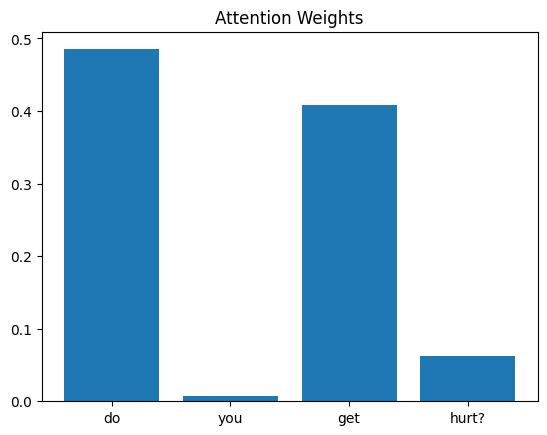

In [ ]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

do you have a gender?  ->  top word: 'do' (0.690) | predicted: I don't have a body.
do you eat cake?  ->  top word: 'eat' (0.563) | predicted: Not at all.
are you interested in ai?  ->  top word: 'interested' (0.839) | predicted: Not at all.


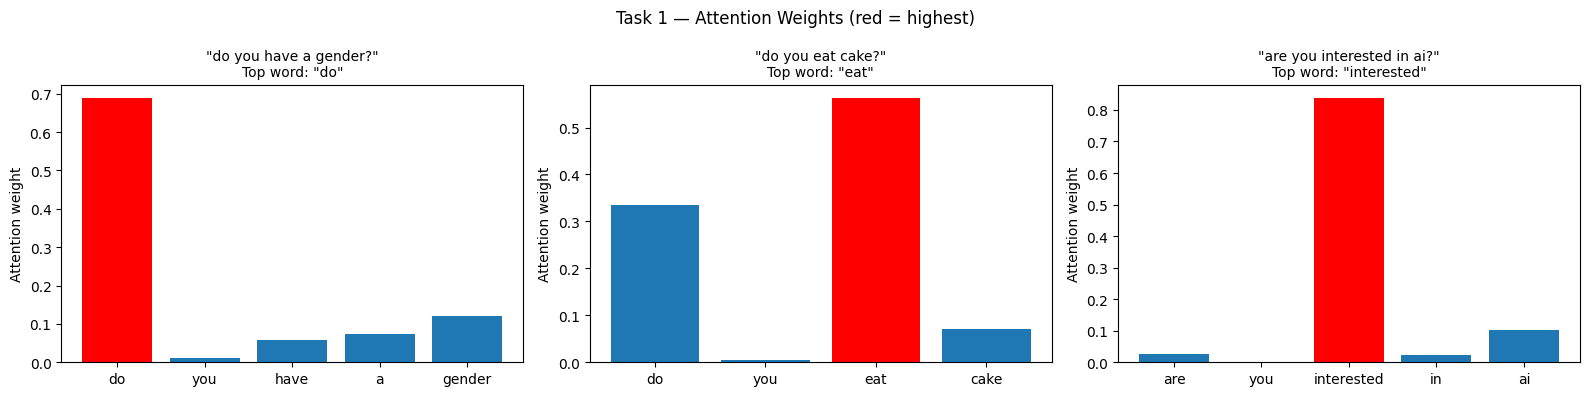

In [ ]:
answers = df.drop_duplicates("answer_id").set_index("answer_id")["answer"]

def get_attention(idx):
    tokens = [t for t in X[idx].tolist() if t != 0]
    words = [tokenizer.index_word[t] for t in tokens]
    with torch.no_grad():
        logits, weights = model(X[idx:idx+1])
    w = weights[0, :len(words)].tolist()
    return words, w, logits.argmax(1).item()

task1_idx = [58, 98, 130]   # "do you have a gender?", "do you eat cake?", "are you interested in ai?"

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, idx in zip(axes, task1_idx):
    words, w, pred = get_attention(idx)
    top = words[w.index(max(w))]
    ax.bar(words, w, color=["red" if x == top else "tab:blue" for x in words])
    ax.set_title(f'"{df["question"][idx]}"\nTop word: "{top}"', fontsize=10)
    ax.set_ylabel("Attention weight")
    print(f"{df['question'][idx]}  ->  top word: '{top}' ({max(w):.3f}) | predicted: {answers[pred]}")

plt.suptitle("Task 1 — Attention Weights (red = highest)")
plt.tight_layout()
plt.show()


### Task 1

I selected three questions from three different answer groups: "do you have a gender?", "do you eat cake?" and "are you interested in AI?". The word with the highest attention weight is highlighted in red in each chart.

Results:
- "do you have a gender?" → highest attention: "do"
- "do you eat cake?" → highest attention: "eat"
- "are you interested in AI?" → highest attention: "interested"

Observations:
- In two of the three questions, the highest attention is on an important word. "eat" tells the model the question is about food, and "interested" tells it the question is about opinions on technology. These words help the model choose the correct answer group.
- In "do you have a gender?", the highest attention is on "do", which is a common function word that appears in many questions. The really important word here is "gender", so in this case the attention does not match what a human would focus on.
- This happens because the model is small, trained for only 50 epochs on 168 questions, and the attention layer is never told which words are important. It only learns weights that reduce the loss.

Conclusion: The words with the highest attention are often important for understanding the question ("eat", "interested"), but not always ("do" instead of "gender"). Attention shows what the model relies on, but it does not always match human understanding, so it is a helpful tool but not a perfect explanation.


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

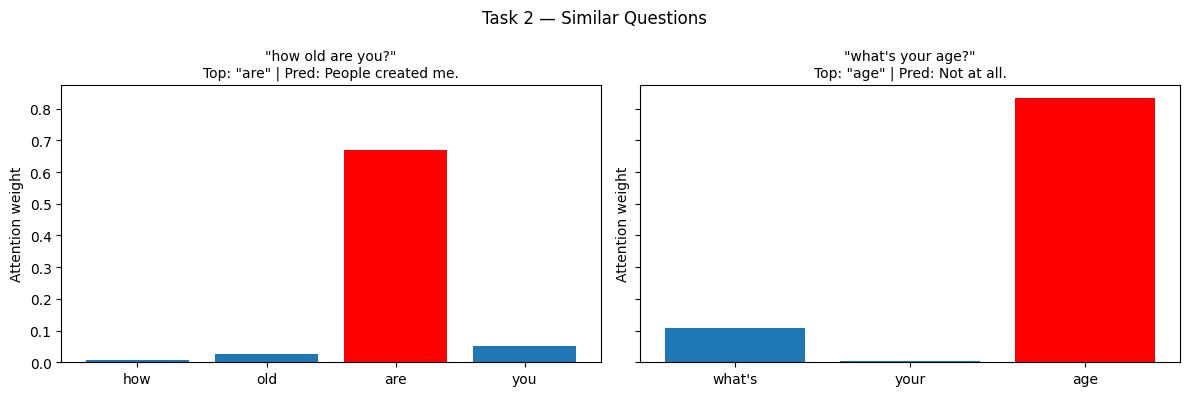

Question 1: how old are you? -> top word: are
Question 2: what's your age? -> top word: age
Same top word? False


In [ ]:
task2_idx = [24, 20]   # "how old are you?" vs "what's your age?"

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
tops = []
for ax, idx in zip(axes, task2_idx):
    words, w, pred = get_attention(idx)
    top = words[w.index(max(w))]
    tops.append(top)
    ax.bar(words, w, color=["red" if x == top else "tab:blue" for x in words])
    ax.set_title(f'"{df["question"][idx]}"\nTop: "{top}" | Pred: {answers[pred]}', fontsize=10)
    ax.set_ylabel("Attention weight")

plt.suptitle("Task 2 — Similar Questions")
plt.tight_layout()
plt.show()

print("Question 1:", df["question"][task2_idx[0]], "-> top word:", tops[0])
print("Question 2:", df["question"][task2_idx[1]], "-> top word:", tops[1])
print("Same top word?", tops[0] == tops[1])


### Task 2

I compared "how old are you?" and "what's your age?". Both belong to the same answer group ("Age doesn't really apply to me."), so they have the same meaning, but they share no words.

Observations:
- The model focuses on different words in each question. In "what's your age?" the highest attention is on "age", which is the key word that carries the meaning. In "how old are you?" the highest attention is on "are", a common function word, instead of the meaningful word "old".
- Even though the model focuses on different words, it predicts the same answer for both questions.

What this suggests about attention:
1. Attention is input-dependent: the weights are calculated again for every sentence, so the model decides where to look based on the words in front of it.
2. Attention does not always match human intuition: in the second question it focused correctly on "age", but in the first it focused on "are" instead of "old". The model is small and trained for only 50 epochs, and attention only learns weights that reduce the loss, not which words humans find important.
3. Attention is a weighted summary: the output is the sum of (weight × hidden state), so the model still uses information from all words, not only the top one. This is why it can still give the correct answer even when the top word is not the most meaningful one.


